In [86]:
from google.colab import files

uploaded = files.upload()

Saving Retail_Sales_Data.csv to Retail_Sales_Data (2).csv


   Unnamed: 0                              Sales_ID Product_Category  \
0           0  efc35a5f-e48c-4803-9f6d-ef32a60e1367           Movies   
1           1  92a86e42-de42-4e0d-89f3-bbb0b7f354bd     Pet Supplies   
2           2  1fbbdc48-f405-48f3-8274-750581552d26          Outdoor   
3           3  1f329e7a-13f0-4518-9eeb-84815301d64c      Electronics   
4           4  6ef559dc-3e68-4009-9845-4bab54d897c6            Books   

   Sales_Amount  Discount      Sales_Region Date_of_Sale  Customer_Age  \
0        341.05     45.98    East Dianeport   2024-07-12          69.0   
1        594.71     29.59       North Linda   2024-05-07          32.0   
2        351.90     49.78  Lake Josephmouth   2024-05-11          28.0   
3           NaN       NaN  North Martinside   2024-09-02           NaN   
4        795.75     27.21      Michealshire   2024-05-02          21.0   

  Customer_Gender Sales_Representative  
0            Male      Bruce Rodriguez  
1           Other        Patricia Pugh  

/tmp/ipykernel_3874/1742660000.py:15: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['Sales_Amount'].fillna(df['Sales_Amount'].mean(), inplace=True)
/tmp/ipykernel_3874/1742660000.py:16: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, 

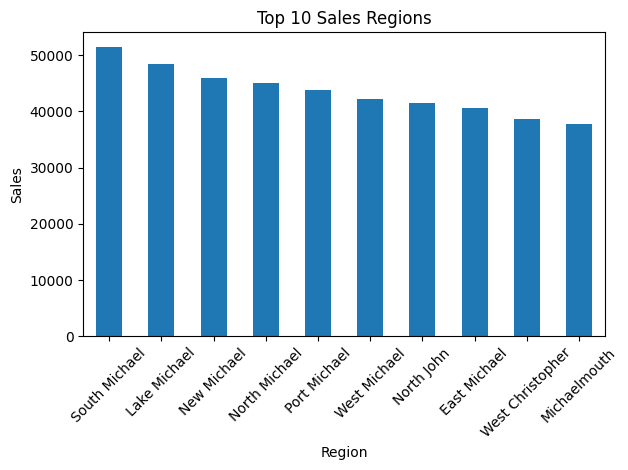

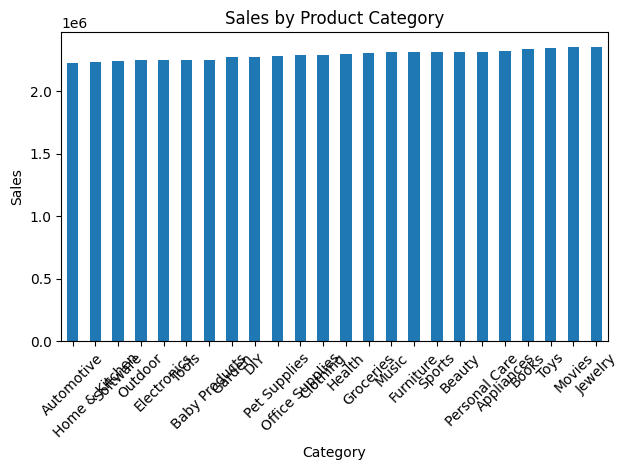

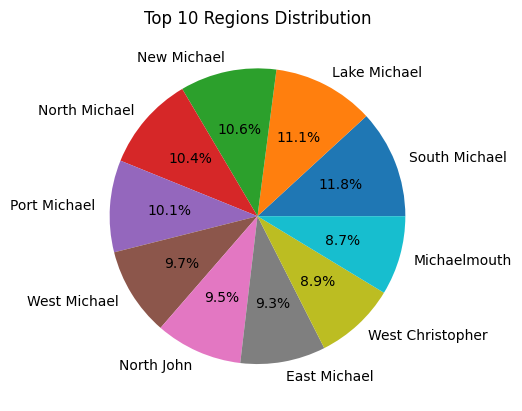

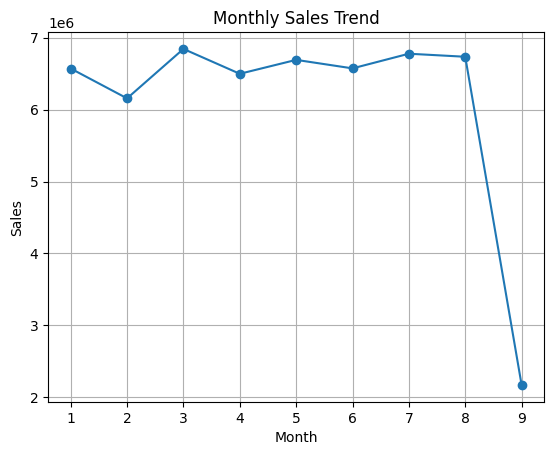

In [88]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. Import
df = pd.read_csv('Retail_Sales_Data.csv')
print(df.head())

# 2. Explore
print(df.shape)
print(df.info())
print(df.isnull().sum())

# 3. Cleaning - Simple
df = df.drop(columns=['Unnamed: 0'], errors='ignore')
df['Sales_Amount'].fillna(df['Sales_Amount'].mean(), inplace=True)
df['Discount'].fillna(df['Discount'].median(), inplace=True)
df['Customer_Age'].fillna(df['Customer_Age'].median(), inplace=True)
df['Customer_Gender'].fillna(df['Customer_Gender'].mode()[0], inplace=True)
df['Date_of_Sale'] = pd.to_datetime(df['Date_of_Sale'])
df['Month'] = df['Date_of_Sale'].dt.month

# 4. Aggregation - Simple
region_sales = df.groupby('Sales_Region')['Sales_Amount'].sum()
category_sales = df.groupby('Product_Category')['Sales_Amount'].sum()

print("\nTotal Sales by Region (Top 10):")
print(region_sales.sort_values(ascending=False).head(10))

print("\nSales by Category:")
print(category_sales.sort_values(ascending=False))

print("\nTotal Sales:", df['Sales_Amount'].sum())
print("Top Region:", region_sales.idxmax())

# 5. Visualization
# Bar - Top 10 Regions
region_sales.sort_values(ascending=False).head(10).plot(kind='bar')
plt.title('Top 10 Sales Regions')
plt.xlabel('Region')
plt.ylabel('Sales')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Bar - Category
category_sales.sort_values().plot(kind='bar')
plt.title('Sales by Product Category')
plt.xlabel('Category')
plt.ylabel('Sales')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Pie - Region
region_sales.sort_values(ascending=False).head(10).plot(kind='pie', autopct='%1.1f%%')
plt.title('Top 10 Regions Distribution')
plt.ylabel('')
plt.show()

# Line - Monthly Trend
df.groupby('Month')['Sales_Amount'].sum().plot(marker='o')
plt.title('Monthly Sales Trend')
plt.xlabel('Month')
plt.ylabel('Sales')
plt.grid()
plt.show()